In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection, Poly3DCollection
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler

from IPython.display import display, Markdown

from tqdm import tqdm

import copy

from utilities import *

plt.rcParams["axes3d.mouserotationstyle"] = "azel"

In [2]:
### Generate training data

mesh_data = MeshData(n=10)

sampler = FixedTopologySampleGenerator(
    mesh_data,
)

In [3]:
X_train, q_vecs = sampler.sample_batch(2048)

torch.save(
    {
        "X_train": X_train,
        "q_vecs": q_vecs,
    },
    "training data/2048_batch_10x10_train.pt",
)

X_val, q_vecs = sampler.sample_batch(2048)

torch.save(
    {
        "X_train": X_val,
        "q_vecs": q_vecs,
    },
    "validation data/2048_batch_10x10_test.pt",
)

In [5]:
### Train

validation_data_path = "validation data/2048_batch_10x10_test.pt"
validation_data = torch.load(validation_data_path)
validation_ds = TensorDataset(validation_data["X_train"], validation_data["q_vecs"])

topology = MeshData(n=10)

model = ForceDensityPredictorPINN(
    topology=topology,
    act_fn=nn.Tanh(),
    hidden_sizes=(256, 256),
    min_q=0.05,
    max_q=40,
)

# with profile(activities=[ProfilerActivity.CPU]) as prof:
history = train_adaptive(
    model=model,
    data_loss_fn=pointwise_Lp_loss,
    data=validation_ds,
    data_generator=sampler,
    data_loss_parameters=(2.0,),
    train_val_test=(0, 0.5, 0.5),
    # physics_loss_fn=FDM_physics_loss,
    # t_colloc=None,
    # physics_loss_parameters=(),
    epochs=5000,
    # weighting=LossWeighting(lambda_data=1, lambda_physics=0.1),
    early_stop_patience=100,
)

# print(prof.key_averages().table(sort_by="self_cpu_time_total", row_limit=15))

Training:  75%|███████▌  | 3766/5000 [16:57<05:33,  3.70it/s, Train=0.095846, Val=0.095399]

Early stopping at epoch 3766


In [11]:
p_mats = validation_data["X_train"][:, topology.free_ind, 4:]
hat_qs = model(
    validation_data["X_train"].reshape((validation_data["X_train"].shape[0], -1))
)
hat_X = topology.eq_shape_batched(hat_qs, p_mats)
X = validation_data["X_train"][:, :, :3]

err = torch.linalg.norm((hat_X - X), dim = 2).amax(dim=1)

print(err)
print(torch.max(err))

max_err_row = torch.argmax(err)

print(max_err_row)

Xs_0 = validation_data["X_train"][max_err_row, :, :]
qs_0 = validation_data["q_vecs"][max_err_row, :]
P_mat_0 = Xs_0[topology.free_ind, 4:]

qs_hat = model(Xs_0.ravel())

X_eq = Xs_0[:, :3]  # topology.eq_shape(qs_0, P_mat_0)
X_hat = topology.eq_shape(qs_hat, P_mat_0)

%matplotlib qt
visualize_mesh(topology, X_eq, X_hat)

tensor([0.0871, 0.0812, 0.1018,  ..., 0.1071, 0.0785, 0.0876],
       grad_fn=<AmaxBackward0>)
tensor(0.3371, grad_fn=<MaxBackward1>)
tensor(1060)


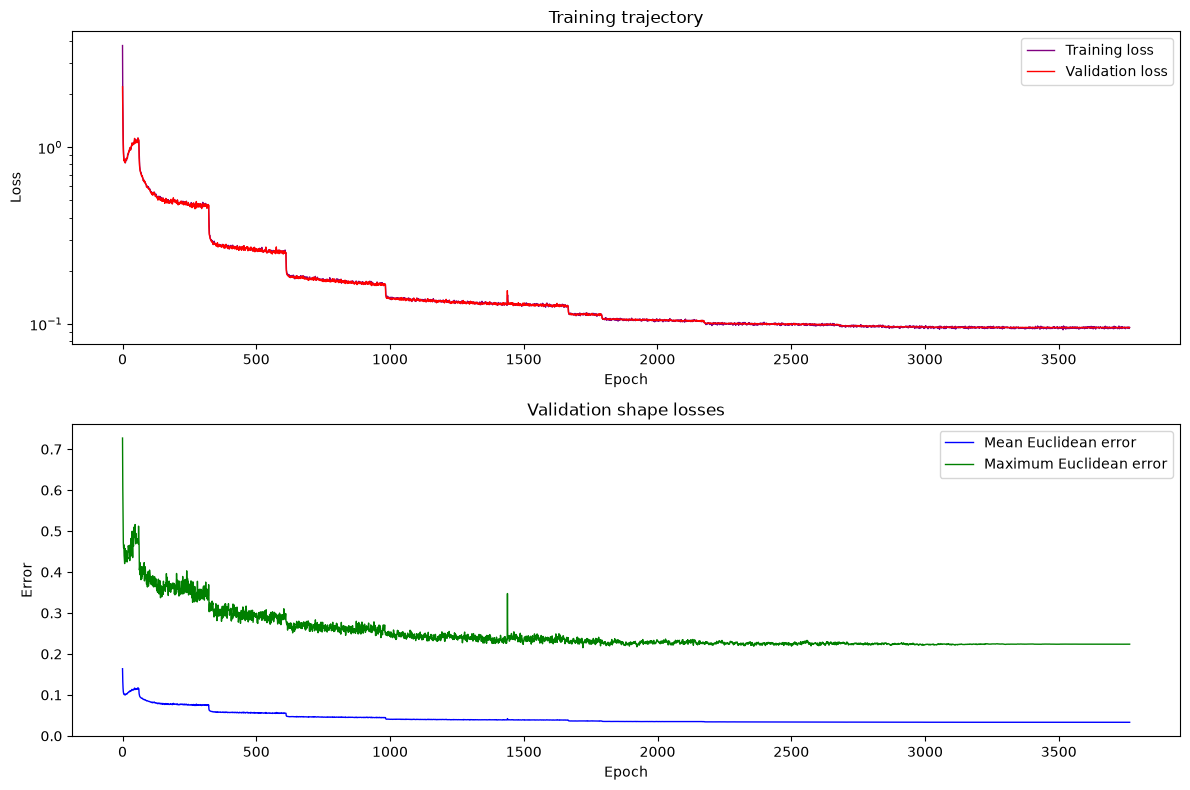

In [19]:
plt.close('all')
%matplotlib inline

fig, axs = plt.subplots(2, 1, figsize=(12, 8))

###

# axs[0].plot(
#     history["data_train"],
#     color="blue",
#     lw=0.5,
#     label="Training data loss",
# )
# axs[0].plot(
#     history["physics_train"],
#     color="green",
#     lw=0.5,
#     label="Training physics loss",
# )

axs[0].plot(
    history["total_train"],
    color="purple",
    lw=1.0,
    label="Training loss",
)

axs[0].plot(
    history["total_val"],
    color="red",
    lw=1.0,
    label="Validation loss",
)
axs[0].set_title("Training trajectory")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
axs[0].legend()

axs[0].set_yscale("log")

###

axs[1].plot(
    history["mean_dist_val"],
    color="blue",
    lw=1.0,
    label="Mean Euclidean error",
)

axs[1].plot(
    history["max_dist_val"],
    color="green",
    lw=1.0,
    label=r"Maximum Euclidean error",
)

axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Error")

axs[1].set_title("Validation shape losses")
axs[1].legend()

fig.tight_layout()

In [13]:
print(f"{history["mean_dist_test"] =}")
print(f"{history["max_dist_test"] =}")

history["mean_dist_test"] =[0.03332994505763054]
history["max_dist_test"] =[0.234593965113163]
